#Learning Corrections to Drone Motion Models

This project investigates whether a learned residual correction improves a simplified thrust model's predictions of quadrotor body-frame acceleration, and whether the improvement varies with flight speed. The experiment compares five approaches on recorded NeuroBEM flights: ordinary least squares, a thrust baseline, ridge regression, a direct neural network, and a residual neural network.

### Data Acquisition and Flight-Level Split

The processed NeuroBEM dataset contains flight recordings divided into CSV segments. To prevent data leakage, all segments from a given flight are assigned to the same split. Every flight referenced in the authors' test list is held out in full. The remaining flights are divided into training and validation sets in approximately 80/20 split using a fixed random seed of 42.

In [2]:
# downloading the NeuroBEM flight archive and the authors' test list.
# in colab, ! runs a shell command. The -c flag resumes a partial download,
# and -nv keeps the download output short
!wget -c -nv https://download.ifi.uzh.ch/rpg/NeuroBEM/processed_data.zip
!wget -c -nv https://download.ifi.uzh.ch/rpg/NeuroBEM/testset.txt

from pathlib import Path
from zipfile import ZipFile

import pandas as pd
from sklearn.model_selection import train_test_split

def get_flight_id(filename):
  # we take the base filename, we drop its extension, and remove the ZIP prefix
  stem = Path(filename).stem.removeprefix("merged_")
  # we drop the segment suffix so all segments share their original flight ID
  return stem.split("_seg_", 1)[0]

# reading the ZIP archive's file listing directly. Keeping the csv files and
# skipping the metadata folder that macOS sometimes adds to zip archives
with ZipFile("processed_data.zip") as archive:
  files = sorted(
      name for name in archive.namelist()
      if name.endswith(".csv") and not name.startswith("__MACOSX/")
  )

# making a table with one row per CSV segment. The "file" column keeps the
# path inside the ZIP so the preprocessing cell can open it later
splits = pd.DataFrame({"file": files})
splits["flight_id"] = splits["file"].map(get_flight_id)

# the authors' test list names individual segments. Here we are converting
# those names to flight IDs so every segment from a listed flight goes into
# the test set. This prevents segments of the same flight from appearing in
# multiple splits. A set keeps each flight ID only once, even if several
# segments are listed
test_ids = {
    get_flight_id(line.strip())
    for line in Path("testset.txt").read_text().splitlines()
    if line.strip()
}

# confirming that the test list contains at least one flight and that every
# listed test flight is present in the archive
all_ids = set(splits["flight_id"])
assert test_ids and test_ids <= all_ids, "The test list must match the flight archive"

# after setting aside the test flights, assigning roughly 80% of the remaining
# flights to training and 20% to validation. Sorting and using a fixed random
# seed make the assignments reproducible across runs
train_ids, val_ids = train_test_split(
    sorted(all_ids - test_ids), test_size = 0.2, random_state = 42
)

# mapping each flight ID to its split, then copy that assignment to every
# segment belonging to the flight
assignment = dict.fromkeys(train_ids, "train")
assignment.update(dict.fromkeys(val_ids, "validation"))
assignment.update(dict.fromkeys(test_ids, "test"))
splits["split"] = splits["flight_id"].map(assignment)

# saving the segment-to-split assignments so the exact split can be inspected
# and reused later. Create the results folder if needed
Path("results").mkdir(exist_ok=True)
splits.to_csv("results/flight_splits.csv", index=False)

# count unique flights in each split. A flight with several CSV segments
# contributes one to the count
display(splits.groupby("split")["flight_id"].nunique().to_frame("Flights"))


2026-11-13 23:48:01 URL:https://download.ifi.uzh.ch/rpg/NeuroBEM/processed_data.zip [657316788/657316788] -> "processed_data.zip" [1]
2026-11-13 23:48:03 URL:https://download.ifi.uzh.ch/rpg/NeuroBEM/testset.txt [338/338] -> "testset.txt" [1]


,Flights
split,
test,13
train,65
validation,17


## Data Preprocessing and Feature Construction

Training and validation segments are loaded according to the flight-level split defined above. Every eighth observation within each segment is retained to reduce computational cost. The retained values are checked for finiteness. Timestamps, flight IDs, and segment filenames are preserved for time-series plots and per-flight evaluation.

Each observation has 10 input features comprising three linear velocity components, three angular velocity components, and four squared motor speeds. The prediction targets are the recorded body-frame acceleration components x, y, and z axes. The sum of the four squared motor speeds is computed separately for the thrust baseline.

In [3]:
import numpy as np
import pandas as pd
from zipfile import ZipFile

# modeling inputs: linear velocity, angular velocity, and four motor speeds
velocity_cols = ["vel x", "vel y", "vel z"]
rate_cols = ["ang vel x", "ang vel y", "ang vel z"]
motor_cols = ["mot 1", "mot 2", "mot 3", "mot 4"]

# predicting the recorded body-frame acceleration along all three axes
target_cols = ["acc x", "acc y", "acc z"]

# keeping the recorded timestamp for plotting acceleration over time
keep_cols = ["t", *velocity_cols, *rate_cols, *motor_cols, *target_cols]

def load_split(split_name):
  frames = []

  # the split table from the previous cell assigns all segments of
  # each flight to the same split. Selecting the files for this split.
  selected = splits.loc[splits["split"] == split_name]

  # read one flight segment at a time directly from the ZIP archive
  with ZipFile("processed_data.zip") as archive:
    for row in selected.itertuples(index=False):
      with archive.open(row.file) as stream:
        frame = pd.read_csv(stream)

      # cleaning extra spaces and any leading "#" from the column names
      frame.columns = frame.columns.str.strip().str.lstrip("#").str.strip()

      # keeping the relevant columns and sample every eighth row within
      # each segment to reduce the number of observations processed
      frame = frame[keep_cols].iloc[::8].copy()

      # checking that the sampled data has rows and contains finite values
      if frame.empty or not np.isfinite(frame.to_numpy(dtype=float)).all():
        raise ValueError(f"Check numeric data in {row.file}")

      # saving the original flight ID for per-flight metrics and the
      # segment filename for plotting each segment separately
      frame["flight_id"] = row.flight_id
      frame["segment"] = row.file
      frames.append(frame)

  # combining the segments into one DataFrame with a fresh row index
  return pd.concat(frames, ignore_index=True)

def make_arrays(frame):
  # squaring each motor speed individually because the thrust approximation
  # models each rotor's contribution as proportional to its speed squared
  motor_squared = frame[motor_cols].to_numpy(dtype=float) ** 2

  # building 10 features: 3 linear velocities, 3 angular velocities
  # and 4 squared motor speeds
  features = np.column_stack((frame[velocity_cols + rate_cols], motor_squared))

  #each row has three acceleration targets: x, y, and z
  targets = frame[target_cols].to_numpy(dtype=float)

  return features, targets, motor_squared.sum(axis = 1)

# loading the data used to fit the models and select their settings
train = load_split("train")
val = load_split("validation")

# X holds the features before scaling, y holds the acceleration targets
# and s holds the motor-speed sum used by the thrust baseline
X_train_raw, y_train, s_train = make_arrays(train)
X_val_raw, y_val, s_val = make_arrays(val)

# checking for 10 feature columns, 3 target columns, and matching row counts
print("Training shapes", X_train_raw.shape, y_train.shape)
print("Validation shapes", X_val_raw.shape, y_val.shape)

Training shapes (157092, 10) (157092, 3)
Validation shapes (35590, 10) (35590, 3)


### Data Quality Audit

This audit reads every original CSV segmnt before subsampling. It cheks for required columns, counts missing values and nonfinite rows in the fields used by the experiment, and detects exact duplicate rows across all columns.

Within each segment, it also counts repeated timestamps and backward time steps and reports the median positive sampling interval. The segment-level results are saved to `results/data_audit.csv`

In [4]:
from zipfile import ZipFile

# auditing the original CSV rows in every segment listed in the split table
audit_rows = []

with ZipFile("processed_data.zip") as archive:
  for file in splits["file"]:
    with archive.open(file) as stream:
      frame = pd.read_csv(stream)

    # normalizing the csv headers the same way as the preprocessing cell
    frame.columns = frame.columns.str.strip().str.lstrip("#").str.strip()

    # checking that the segment has the timestamp, features, and targets we use
    missing_cols = set(keep_cols) - set(frame.columns)

    if missing_cols:
      raise ValueError(f"{file} is missing columns {sorted(missing_cols)}")

    used = frame[keep_cols]
    values = used.to_numpy(dtype=float)
    time = used["t"].to_numpy(dtype=float)

    # comparing adjacent timestamps within this segment in their original order
    # positive, finite differences measure the time between observations
    dt = np.diff(time)
    positive_dt = dt[np.isfinite(dt) & (dt > 0)]

    # counting missing cells and nonfininte rows in the columns used by the notebook
    # checking for exact duplicate rows across all columns in the original CSV
    # a repeated timestamp can occur even when the rest of the row differs
    audit_rows.append({
        "file": file,
        "rows": len(frame),
        "missing_values": int(used.isna().sum().sum()),
        "nonfinite_rows": int(((~np.isfinite(values).all(axis=1)).sum())),
        "duplicate_rows": int(frame.duplicated().sum()),
        "repeated_timestamps": int(pd.Series(time).dropna().duplicated().sum()),
        "backward_time_steps": int((dt < 0).sum()),
        "median_positive_dt_s": np.median(positive_dt) if positive_dt.size else np.nan
    })

  # saving one row per segment so any issue can be traced to its source file
  data_audit = pd.DataFrame(audit_rows)
  data_audit.to_csv("results/data_audit.csv", index=False)

  # summing the counts across segments and summarize their median time steps separately
  count_columns = [
      "rows", "missing_values", "nonfinite_rows", "duplicate_rows",
      "repeated_timestamps", "backward_time_steps",
  ]

  print(f"Segments checked: {len(data_audit)}")
  display(data_audit[count_columns].sum().to_frame("Archive totals"))
  display(data_audit["median_positive_dt_s"].describe().to_frame("Time step (s)"))


Segments checked: 247


,Archive totals
rows,1798481
missing_values,0
nonfinite_rows,0
duplicate_rows,0
repeated_timestamps,0
backward_time_steps,0


,Time step (s)
count,247.000000
mean,0.002558
std,0.000455
min,0.002500
25%,0.002500
50%,0.002500
75%,0.002500
max,0.006098


## Baseline Models

The thrust baseline predicts body-frame acceleration as (0, 0, c*s), where s is the sum of the four squared motor speeds. The coefficient c is fitted by least squares on the training data.

Ridge regression uses all ten features to predict the three acceleration components. Feature scaling is fitted on the training set and applied to the validation set. The ridge penalty is selected by minimizing RMSE.

In [5]:
from sklearn.linear_model import Ridge
from sklearn.preprocessing import StandardScaler

# fitting the feature scaler on training data and reuse it for validation
scaler = StandardScaler().fit(X_train_raw)
X_train = scaler.transform(X_train_raw)
X_val = scaler.transform(X_val_raw)

# fitting a_z = c * s by least squares through the origin
# using the sum of squared motor speeds in its original units
c = (s_train @ y_train[:, 2]) / (s_train @ s_train)

def predict_thrust(s):
  # the simplified thrust model predicts acceleration along body z
  zeros = np.zeros_like(s)
  return np.column_stack((zeros, zeros, c * s))

def rmse(actual, predicted):
  # average squared errors across all observations and all three axes
  return np.sqrt(np.mean((actual - predicted) ** 2))

# save thrust predictions for the residual model
a0_train = predict_thrust(s_train)
a0_val = predict_thrust(s_val)

# fitting eaach ridge candidate on training data and select it on validation
ridge_models = [
    Ridge(alpha=alpha).fit(X_train, y_train)
    for alpha in (1, 100, 10000)
]

ridge = min(
    ridge_models,
    key=lambda model: rmse(y_val, model.predict(X_val))
)

print(f"Thrust validation RMSE: {rmse(y_val, a0_val)}")
print(f"Ridge validation RMSE: {rmse(y_val, ridge.predict(X_val)):.4f} m/s^2")
print(f"Selected ridge alpha: {ridge.alpha}")

Thrust validation RMSE: 1.3313636708529422
Ridge validation RMSE: 0.6630 m/s^2
Selected ridge alpha: 10000


## Direct and Residual Neural Networks

Both models use 10 inputs, one hidden layer with 32 ReLU units, and a linear output layer with three acceleration components. The direct network predicts measured acceleration. The residual network predicts the difference between measured acceleration and the thurst estimate. Its final prediction adds the learned correction to the thurst estimate.

Both networks minimize mean squared error using Adam witha. learning rate of 0.001 and batches of 256 observations. Trainign runs for at most 50 ecpohs, with early stopping after five consecutive epochs without improved validation RMSE. Both models are scored against measured acceleration, and the weights fromt he lowest-RMSE validation epoch are retained.

In [6]:
from copy import deepcopy

import torch
from torch import nn

# putting inputs and vlidation labels on the same device as the models
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
train_inputs = torch.as_tensor(X_train, dtype=torch.float32, device=device)
val_inputs = torch.as_tensor(X_val, dtype=torch.float32, device=device)
val_acceleration = torch.as_tensor(y_val, dtype=torch.float32, device=device)

def fit_network(train_targets, val_baseline=0.0, seed=42, history=None):
  # strating both networks from the same initialization for a given seed
  torch.manual_seed(seed)
  model = nn.Sequential(
      nn.Linear(10, 32),
      nn.ReLU(),
      nn.Linear(32, 3)
  ).to(device)

  # using the same architecture, loss, and optimizer for both networks
  optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
  mse = nn.MSELoss()
  train_targets = torch.as_tensor(train_targets, dtype=torch.float32, device=device)
  val_baseline = torch.as_tensor(val_baseline, dtype=torch.float32, device=device)

  #traacking the best validation epoch and how long it has gone unbeaten
  best_rmse = float("inf")
  best_weights = None
  best_epoch = 0
  epochs_without_improvement=0

  for epoch in range(1, 51):
    model.train()

    # shuffling row indices once per epoch. Using the same indices for inputs
    # and targets so each observation stays paired with its label
    order = torch.randperm(len(train_inputs), device=device)
    for indices in order.split(256):
      optimizer.zero_grad()
      loss = mse(model(train_inputs[indices]), train_targets[indices])
      loss.backward()
      optimizer.step()

    # scoring both models against measured acceleration. The direct model adds
    # zero. The residual model adds the thrust prediction back
    model.eval()
    with torch.no_grad():
      val_predictions = model(val_inputs) + val_baseline
      val_rmse = mse(val_predictions, val_acceleration).sqrt().item()

    # save one validation RMSE per completed epoch for the learning curve
    if history is not None:
      history.append(val_rmse)

    if val_rmse < best_rmse:
      best_rmse = val_rmse
      best_epoch = epoch
      # copying the weights so later optimizer steps cannot modify this checkpoint
      best_weights = deepcopy(model.state_dict())
      epochs_without_improvement = 0
    else:
      epochs_without_improvement += 1
      if epochs_without_improvement == 5:
        break

  if best_weights is None:
    raise RuntimeError("Training did not produce a finite validation RMSE")

  # returning the model from the lowest-RMSE validation epoch
  model.load_state_dict(best_weights)
  return model, best_rmse, best_epoch

# keeping a separate history for each model and seed
direct_history = {42: []}
residual_history = {42: []}

# learning
direct_model, direct_val_rmse, direct_epoch = fit_network(
    y_train, history=direct_history[42]
)

residual_model, residual_val_rmse, residual_epoch = fit_network(
    y_train - a0_train, val_baseline=a0_val, history=residual_history[42]
)

print(f"Direct NN validation RMSE: {direct_val_rmse:.4f} m/s^2 (epoch {direct_epoch})")
print(f"Residual NN validation RMSE: {residual_val_rmse:.4f} m/s^2 (epoch {residual_epoch})")

Direct NN validation RMSE: 0.4029 m/s^2 (epoch 50)
Residual NN validation RMSE: 0.4008 m/s^2 (epoch 16)


### Sensitivity to Random Seed

The direct and residual networks are trained with paired seeds 42, 43, 44. Both use the same data split, architecture, and training settings. The repeated runs show how the comparison varies with weight initialization and minibatch order.

The table reports each model's best validation RMSE for each seed. A negative residual-minus-direct difference indicates lower validation error for the residual network.

In [7]:
# reusing the seed-42 models. Each tuple holds the fitted model, its best
# validation RMSE, and the epoch at which that RMSE was reached
direct_runs = {42: (direct_model, direct_val_rmse, direct_epoch)}
residual_runs = {42: (residual_model, residual_val_rmse, residual_epoch)}

# using the same residual targets for every residual-network run
residual_targets = y_train - a0_train

for seed in (43, 44):
  # giving each run its own list of per-epoch validation errors
  direct_history[seed] = []
  residual_history[seed] = []

  # pairing both models by seed while keeping the data and training settings fixed
  direct_runs[seed] = fit_network(
      y_train, seed=seed, history=direct_history[seed]
  )
  residual_runs[seed] = fit_network(
      residual_targets, val_baseline=a0_val, seed=seed,
      history=residual_history[seed]
  )

# reading the best validation RMSE from each saved run tuple
validation_by_seed = pd.DataFrame([
    {
        "Seed": seed,
        "Direct RMSE": direct_runs[seed][1],
        "Residual RMSE": residual_runs[seed][1]
    }
    for seed in (42, 43, 44)
]).set_index("Seed")

# a negative difference means the residual network had lower validation RMSE
validation_by_seed["Residual minus Direct"] = (
    validation_by_seed["Residual RMSE"] - validation_by_seed["Direct RMSE"]
)

display(validation_by_seed.round(4))


,Direct RMSE,Residual RMSE,Residual minus Direct
Seed,,,
42,0.4029,0.4008,-0.0021
43,0.3958,0.3823,-0.0134
44,0.4005,0.3751,-0.0254


### Validation Learning Curves
Each panel shows validation acceleration RMSE by epoch for the direct and residual networks trained with the same seed. All panels share the same vertical scale. The marked points identify the checkpoints used for held-out test evaluation. Curves can end at different epochs because each run applies early stopping independently.

the figure is saved to `results/learning_curves.png`, and the per-epoch values are saved to `results/learning_curves.csv`

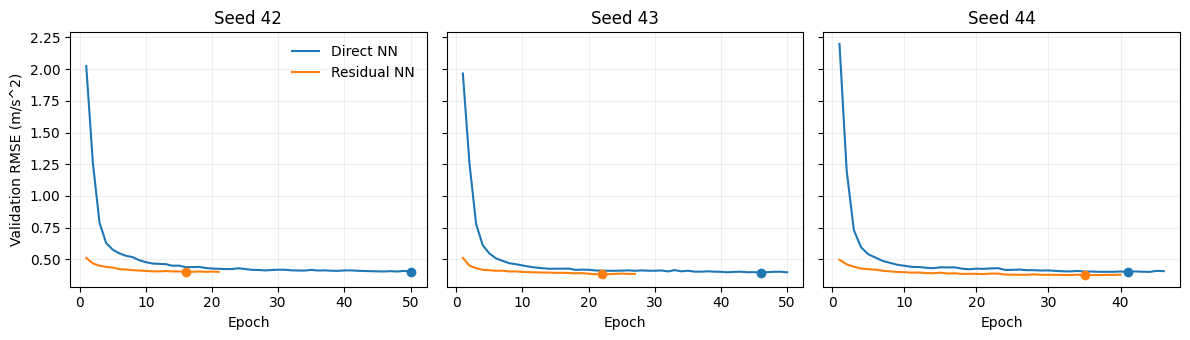

In [8]:
import matplotlib.pyplot as plt

# using one panel per seed and a shared y-axis for direct comparison
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5), sharey=True)
curve_rows = []

for ax, seed in zip(axes, (42, 43, 44)):
  for label, histories, runs in (
      ("Direct NN", direct_history, direct_runs),
      ("Residual NN", residual_history, residual_runs),
  ):
    # using each run's actual number of epochs, including early stopping
    history = histories[seed]
    epochs = range(1, len(history) + 1)
    _, best_rmse, best_epoch = runs[seed]

    #marking the epochs whose weights were retained for held-out evaluation
    line, = ax.plot(epochs, history, label=label)
    ax.scatter(best_epoch, best_rmse, color=line.get_color(), zorder=3)

    # saving one record per model, seed, and completed epoch
    curve_rows.extend(
        {"Model": label, "Seed": seed, "Epoch": epoch, "Validation RMSE": value}
        for epoch, value in zip(epochs, history)
    )
  ax.set_title(f"Seed {seed}")
  ax.set_xlabel("Epoch")
  ax.grid(alpha=0.2)

axes[0].set_ylabel("Validation RMSE (m/s^2)")
axes[0].legend(frameon=False)
fig.tight_layout()

# saving the figure for the report and the underlying values for reproducibility
fig.savefig("results/learning_curves.png", dpi=180)
pd.DataFrame(curve_rows).to_csv("results/learning_curves.csv", index=False)
plt.show()

## Held-Out Test Evaluation

All five approaches are evaluated on the same held-out flights. The test features are transformed using the scaler fitted on the training data. RMSE and MAE are reported overall and for each acceleration axis in m/s^2. Each neural network is scored separately for each seed, and the resulting metrics are averaged across the three runs.

In [9]:
from sklearn.linear_model import LinearRegression

# prepare the held-out inputs using the training-fitted scaler
test = load_split("test")
X_test_raw, y_test, s_test = make_arrays(test)
X_test = scaler.transform(X_test_raw)
test_inputs = torch.as_tensor(X_test, dtype=torch.float32, device=device)
a0_test = predict_thrust(s_test)

def predict_nn(model):
  model.eval()
  with torch.no_grad():
    return model(test_inputs).cpu().numpy()

# fitting ordinary least squares on the training split
ols = LinearRegression().fit(X_train, y_train)

# storing a prediction array for each model and seed
# adding thrust back to convert the residual predictions to acceleration
test_predictions = {
    "Thrust": {None: a0_test},
    "Linear regression": {None: ols.predict(X_test)},
    "Ridge": {None: ridge.predict(X_test)},
    "Direct NN": {
        seed: predict_nn(run[0]) for seed, run in direct_runs.items()
    },
    "Residual NN": {
        seed: a0_test + predict_nn(run[0])
        for seed, run in residual_runs.items()
    },
}

def score_predictions(actual, predicted):
  absolute_error = np.abs(actual - predicted)
  scores = {"RMSE": rmse(actual, predicted), "MAE": absolute_error.mean()}

  for column, axis in enumerate("xyz"):
    scores[f"RMSE {axis}"] = rmse(actual[:, column], predicted[:, column])
    scores[f"MAE {axis}"] = absolute_error[:, column].mean()

  return scores

# scoring each run before averaging its metrics across seeds

test_by_run = pd.DataFrame([
    {"Model": name, "Seed": seed, **score_predictions(y_test, prediction)}
    for name, runs in test_predictions.items()
    for seed, prediction in runs.items()
])

grouped = test_by_run.drop(columns="Seed").groupby("Model", sort=False)
test_metrics = grouped.mean()
test_metrics["RMSE SD"] = grouped["RMSE"].std()

test_metrics.to_csv("results/test_metrics.csv", float_format="%.8g")
display(test_metrics.round(4))

,RMSE,MAE,RMSE x,MAE x,RMSE y,MAE y,RMSE z,MAE z,RMSE SD
Model,,,,,,,,,
Thrust,1.7365,0.9512,1.5762,0.9307,1.6419,0.9100,1.9663,1.0129,NaN
Linear regression,0.8783,0.4749,0.6154,0.3541,0.5456,0.3251,1.2799,0.7454,NaN
Ridge,0.9193,0.4708,0.6361,0.3414,0.5759,0.3128,1.3412,0.7581,NaN
Direct NN,0.4985,0.2748,0.3354,0.2015,0.3175,0.1851,0.7294,0.4379,0.0092
Residual NN,0.4906,0.2667,0.3345,0.2018,0.3145,0.1785,0.7149,0.4198,0.0178


## Test Error by Flight Speed

Flight speed is calculated as the Euclidean norm of the recorded linear velocity. Test observations are grouped into speeds below 5 m/s and speeds at or above 5 m/s. For each group, the evaluation reports RMSE, and the numbers of observations and contributing flights. Neural-network RMSE is computed separately for each seed and then averaged.

Within the higher-speed group, a per-flight comparison counts how often the residual network achives lower RMSE than Ridge and the direct network on the same observations.

In [10]:
# computing one speed per observation from its three recorded velocity
# components. axis=1 takes the euclidean norm across those components
speed = np.linalg.norm(test[velocity_cols].to_numpy(dtype=float), axis=1)

# each flight ID lines up with the same row in y_test and every prediction array
flight_ids = test["flight_id"].to_numpy()

# assigning observations at exactly 5 m/s to the higher-speed group
fast_mask = speed >= 5.0
speed_groups = {"< 5 m/s": speed < 5.0, ">= 5 m/s": fast_mask}

def rmse_by_run(runs, mask):
  # using the same mask for recorded acceleration and each run's predictions
  # so RMSE is computed on matching observations
  actual = y_test[mask]

  # an empty group has undefined RMSE. Return one NaN per run
  if len(actual) == 0:
    return np.full(len(runs), np.nan)

  # computing one RMSE per run across the selected rows and all three axes
  return np.array([
      rmse(actual, prediction[mask]) for prediction in runs.values()
  ])

# building one row for each combination of speed group and model
speed_rows = []
for group, mask in speed_groups.items():
  for name, runs in test_predictions.items():
    scores = rmse_by_run(runs, mask)

    # counting selected observations and distinct contributing flights
    # a flight can contribute observations to both speed groups
    # average the run-level RMSEs and report their sample standard
    # deviation when multiple runs are available
    speed_rows.append({
        "Speed group": group,
        "Model": name,
        "Observations": int(mask.sum()),
        "Flights": len(np.unique(flight_ids[mask])),
        "RMSE": scores.mean(),
        "RMSE SD": scores.std(ddof=1) if len(scores) > 1 else np.nan
    })

# saving the results for the report and round the notebook display
speed_metrics = pd.DataFrame(speed_rows)
speed_metrics.to_csv(
    "results/metrics_by_speed.csv", index=False, float_format="%.8g"
)
display(speed_metrics.round(4))

# finding the flights with at least one observation at or above 5 m/s
# tracking a separate win count for each comparison model
fast_flights = np.unique(flight_ids[fast_mask])
wins = {"Ridge": 0, "Direct NN": 0}

for flight_id in fast_flights:
  # selecting the higher-speed observations from this flight only
  mask = fast_mask & (flight_ids == flight_id)

  # averaging the residual network's per-seed RMSEs on these observations
  residual_score = rmse_by_run(test_predictions["Residual NN"], mask).mean()

  for name in wins:
    # scoring the comparison model on the same observations counting
    # a win when the residual RMSE is strictly lower
    comparison_score = rmse_by_run(test_predictions[name], mask).mean()
    wins[name] += int(residual_score < comparison_score)

# reporting each win count out of the total number of eligible flights

for name, count in wins.items():
  print(
      f"Residual NN has lower RMSE than {name} on "
      f"{count} of {len(fast_flights)} flights with samples at or above 5 m/s"
  )


,Speed group,Model,Observations,Flights,RMSE,RMSE SD
0,< 5 m/s,Thrust,20350,13,0.4955,NaN
1,< 5 m/s,Linear regression,20350,13,0.4349,NaN
2,< 5 m/s,Ridge,20350,13,0.4245,NaN
3,< 5 m/s,Direct NN,20350,13,0.3322,0.0041
4,< 5 m/s,Residual NN,20350,13,0.3369,0.0105
5,>= 5 m/s,Thrust,11884,12,2.7854,NaN
6,>= 5 m/s,Linear regression,11884,12,1.3299,NaN
7,>= 5 m/s,Ridge,11884,12,1.4083,NaN
8,>= 5 m/s,Direct NN,11884,12,0.6963,0.0178
9,>= 5 m/s,Residual NN,11884,12,0.6772,0.0261


Residual NN has lower RMSE than Ridge on 12 of 12 flights with samples at or above 5 m/s
Residual NN has lower RMSE than Direct NN on 10 of 12 flights with samples at or above 5 m/s


## High-Error Flight Analysis

The two held-out flights with the highest residual-network RMSE, averaged across seeds, are selected for inspection. For each flight, the segment with the highest mean residual-network RMSE is plotted using its recorded timestamps.

The acceleration panels show the recorded values and predictions from both networks using seed 42. Each panel reports RMSE for the plotted segment and axis. The speed panel shows where the flight is above or below the 5 m/s threshold.

In [11]:
import matplotlib.pyplot as plt
from ipywidgets import interact

# reading the segment labels and timestamps in test-set row order
# these positions also index flight_ids, speed, y_test, and the predictions

segments = test["segment"].to_numpy()
timestamps = test["t"].to_numpy(dtype=float)

# each seed maps to an array of predicted accelerations for the test set
residual_test_predictions = test_predictions["Residual NN"]

# for each flight, we compute one residual-network RMSE per seed using all
# observations from that flight. Averaging the three scores and sort highest first
flight_rmse = pd.Series(
    {
        flight_id: rmse_by_run(
            residual_test_predictions, flight_ids == flight_id
        ).mean()
        for flight_id in np.unique(flight_ids)
    },
    name="Residual RMSE"
).sort_values(ascending=False)

# selecting the two highest-error flights for the report figures
flight_rmse.index.name = "Flight ID"
worst_flights = flight_rmse.head(2)
display(worst_flights.to_frame().round(4))

def plot_flight(flight_id):
  # marking the test rows belonging to the selected flight
  in_flight = flight_ids == flight_id

  # comparing the segments in this flight by mean residual-network RMSE
  # max returns the segment name with the largest score. Plotting one segment
  # keeps the traces within a single recording
  segment = max(
      np.unique(segments[in_flight]),
      key=lambda name: rmse_by_run(
          residual_test_predictions, in_flight & (segments == name)
      ).mean()
  )

  # converting the flight-and-segment mask to integer row positions
  rows = np.flatnonzero(in_flight & (segments == segment))

  # sorting the positions by recorded time. A stable sort preserves
  # the original order of observations with identical timestamps
  rows = rows[np.argsort(timestamps[rows], kind="stable")]
  time = timestamps[rows]

  # using the same positions to align the recorded accelerations and both
  # predictions. The plotted predictions use 42 for both networks
  actual = y_test[rows]
  direct = test_predictions["Direct NN"][42][rows]
  residual = residual_test_predictions[42][rows]

  # creating three acceleration panels and one speed panel. The shared time
  # axis makes it possible to match prediction errors with flight speed
  fig, axes = plt.subplots(
      4, 1, figsize=(10, 8), sharex=True, constrained_layout=True
  )

  for column, axis_name in enumerate("xyz"):
    # plotting the recorded and predicted values for one body-frame axis
    ax = axes[column]
    ax.plot(time, actual[:, column], color="black", label="Recorded")
    ax.plot(time, direct[:, column], color="tab:blue", label="Direct NN")
    ax.plot(
        time, residual[:, column], color="tab:orange",
        linestyle="--", label="Residual NN"
    )
    ax.set_ylabel(f"$a_{axis_name}$ (m/s^2)")

    # scoring only the plotted segment and axis. These scores describe
    # the seed-42 traces displayed in this panel
    direct_error = rmse(actual[:, column], direct[:, column])
    residual_error = rmse(actual[:, column], residual[:, column])
    ax.set_title(
        f"RMSE Direct {direct_error:.3f}  Residual {residual_error:.3f}",
        loc="left", fontsize=9
    )

  # the same legend applies to all three acceleration panels
  axes[0].legend(ncol=3, frameon=False)

  # plotting speed for the same observations and mark the cutoff used in
  # the speed-group evaluation
  axes[3].plot(time, speed[rows], color = "darkslategray")
  axes[3].axhline(5.0, color="gray", linestyle=":", label="5 m/s cutoff")
  axes[3].set_ylabel("Speed (m/s)")
  axes[3].set_xlabel("Recorded time (s)")

  for ax in axes:
    ax.grid(alpha=0.2)

  # extracting the segment number from the filename so each saved figure
  # identifies its flight, segment, and prediction seed
  segment_number = segment.split("_seg_", 1)[-1].removesuffix(".csv")
  fig.suptitle(f"Flight {flight_id}, segment {segment_number}, seed 42")
  return fig

# exporting the two report figures in descending flight RMSE order
# closing each figure after saving it to release its plotting resources
for number, flight_id in enumerate(worst_flights.index, start = 1):
  fig = plot_flight(flight_id)
  fig.savefig(f"results/flight_comparison_{number}.png", dpi=180)
  plt.close(fig)

# populating the dropdown with all test flights, highest residual RMSE first
# changing the selection calls the same plotting function used for the exports
@interact(flight_id=flight_rmse.index.tolist())
def view_flight(flight_id):
  fig = plot_flight(flight_id)
  plt.show()
  plt.close(fig)

,Residual RMSE
Flight ID,
2021-02-23-17-27-24,1.0653
2021-02-23-22-54-17,0.8988


interactive(children=(Dropdown(description='flight_id', options=('2021-02-23-17-27-24', '2021-02-23-22-54-17',…

## Exporting Trained Model for Isaac Sim

This section exports the direct and residual neural networks trained with seeds 42, 43, 44. Each export uses the weights from the epoch with the lowest validation RMSE. The checkpoint also stores the input feature order, the training-set scaling parameters, and the fitted thrust coefficient.

The Isaac Sim benchmark uses this checkpoint to compare three controllers during braking and hover. The baseline uses the thrust model, while the other two controllers use lateral acceleration estimates from the direct and residual networks.

In [12]:
from pathlib import Path

import numpy as np
from google.colab import files

# saving the exact feature order used during training: linear velocities,
# angular velocities, and the four motor inputs. The simulator squares
# the motor speeds before applying the scaler, just as the notebook does
checkpoint = {
    "input_columns": np.array(velocity_cols + rate_cols + motor_cols),
    # saving the training-set mean and scale for each feature so the simulator
    # can reproduce the inputs seen by the trained networks
    "scaler_mean": scaler.mean_,
    "scaler_scale": scaler.scale_,

    # the thrust model multiplies the sum of squared motor speeds by c
    # to estimate acceleration along the quadrotor's body z axis
    "thrust_coefficient": np.array(c)
}

# each run stores the fitted model, its best validation RMSE, and its
# best epoch. Index 0 selects the model with its best weights restored
for name, runs in (("direct", direct_runs), ("residual", residual_runs)):
  for seed in (42, 43, 44):
    model = runs[seed][0]

    # saving each layer's weights and biases under a key that identifies the
    # model, seed, and layer, such as "residual_42_0.weight"
    for layer, parameter in model.state_dict().items():
      # detaching from gradient tracking and move to the CPU so the
      # tensor can be saved as a NumPy array
      checkpoint[f"{name}_{seed}_{layer}"] = parameter.detach().cpu().numpy()

# storing all six networks and their shared preprocessing settings in
# one compressed file
path = Path("results/neurobem_dynamics.npz")
path.parent.mkdir(exist_ok=True)
np.savez_compressed(path, **checkpoint)
files.download(str(path))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Isaac Sim braking and gust recovery

This video replays a 24-second Isaac Sim flight from an initial speed of 6 m/s using seed 42. Isaac Sim computed the quadrotor motion, and Python rendered the saved poses alongside synchronized tracking-error plots.

Across seeds 42-44, mean position-tracking RMSE was 19.9 cm for the thrust baseline, 10.9 cm for the direct network, and 11.1 cm for the residual network. Mean RMSE after the hover gust rounded to 10.3 cm for all three controllers.

In [13]:
from pathlib import Path
from IPython.display import Video, display

# playing the finished MP4 from Colab's session storage
video_path = Path("/content/quadrotor_showcase.mp4")

if video_path.is_file():
  display(Video(str(video_path), embed=True, width=960))
else:
  print("Upload quadrotor_showcase.mp4 in the Files sidebar and rerun this cell.")

Upload quadrotor_showcase.mp4 in the Files sidebar and rerun this cell.


In [14]:
from scipy.stats import binomtest
import numpy as np

# comparing both networks on the same high-speed observations in each flight
# averaing the three seed-level RMSEs before comparing the networks
rows = []
for flight_id in np.unique(flight_ids[fast_mask]):
  mask = fast_mask & (flight_ids == flight_id)
  direct = rmse_by_run(test_predictions["Direct NN"], mask).mean()
  residual = rmse_by_run(test_predictions["Residual NN"], mask).mean()
  rows.append((flight_id, direct, residual))

paired = pd.DataFrame(rows, columns=["Flight ID", "Direct RMSE", "Residual RMSE"])
paired["Residual minus direct"] = paired["Residual RMSE"] - paired["Direct RMSE"]
display(paired.round(4))

delta = paired["Residual minus direct"].to_numpy()

# negative differences favor the residual network. Excluding ties from the sign test
non_ties = delta[~np.isclose(delta, 0, rtol = 0, atol=1e-12)]
wins = int((non_ties < 0).sum())
print(f"Residual wins: {wins}/{len(delta)} flights")

if len(non_ties):
  result = binomtest(wins, len(non_ties), p=0.5, alternative="two-sided")
  print(f"Exact paired sign-test p-value: {result.pvalue:.4f}")

# resampling whole flight differences, giving each flight equal weight
rng = np.random.default_rng(42)
bootstrap = rng.choice(delta, size=(20_000, len(delta)), replace=True).mean(axis=1)
lo, hi = np.quantile(bootstrap, [0.025, 0.975])

print(f"Mean per-flight RMSE change: {delta.mean():+.4f} m/s^2")
print(f"Approximate 95% bootstrap CI: [{lo:+.4f}, {hi:+.4f}] m/s^2")

,Flight ID,Direct RMSE,Residual RMSE,Residual minus direct
0,2021-02-18-13-44-23,0.4262,0.4161,-0.0100
1,2021-02-18-16-53-35,0.6571,0.6726,0.0155
2,2021-02-18-17-03-20,0.2312,0.1613,-0.0698
3,2021-02-18-17-19-08,0.4524,0.4322,-0.0202
4,2021-02-18-17-26-00,0.6584,0.6232,-0.0352
5,2021-02-18-18-08-45,0.3343,0.3120,-0.0224
6,2021-02-23-11-41-38,0.3358,0.3102,-0.0256
7,2021-02-23-14-21-48,0.5399,0.5139,-0.0260
8,2021-02-23-17-27-24,1.1360,1.0572,-0.0789
9,2021-02-23-19-45-06,0.6463,0.5977,-0.0486


Residual wins: 10/12 flights
Exact paired sign-test p-value: 0.0386
Mean per-flight RMSE change: -0.0260 m/s^2
Approximate 95% bootstrap CI: [-0.0430, -0.0083] m/s^2


## Conclusion

Ordinary least squares reduced overall acceleration RMSE on the held-out NeuroBEM flights from 1.7365 to 0.8783 m/s^2 relative to the thrust baseline, a 49% reduction. Below 5 m/s, ridge regression was the best linear model at 0.4245 m/s^2. The direct network achieved the lowest RMSE in that speed group at 0.3322 m/s^2, about 22% below ridge. The residual network was close at 0.3369 m/s^2.

At 5 m/s and above, ordinary least squares was the best linear model at 1.3299 m/s^2. The residual network had the lowest RMSE at 0.6772 m/s^2, a 2.7% reduction relative to the direct high-speed observations. Giving each flight equal weight, the mean residual-minus-direct difference was -0.0260 m/s^2, with an approximate 95% bootstrap confidence interval of [-0.0430, -0.0083] m/s^2. The two-sided exact paired sign test gave p = 0.0386. This comparison provides exploratory evidence that residual learning modestly improves acceleration prediction at higher speeds.

In the Isaac Sim trials that started at 6 m/s, mean position-tracking RMSE across three seeds was 19.9 cm for the thrust baseline, 10.9 cm for the direct network, and 11.1 cm for the residual network. Both learned controllers tracked the reference more closely than the thrust baseline over the full trial. After the hover gust, mean RMSE rounded to 10.3 cm for all three controllers.